---
title: "Chronic Kidney Disease Prediction"
description: " "
date: 2023-06-16
categories: [Deep Learning, Classification]
image: images/ckd.jpg
---

<ol class="breadcrumb">
  <li class="breadcrumb-item"><a href="../../index.qmd">Home</a></li>
  <li class="breadcrumb-item"><a href="../ai/index.qmd">Artificial Intelligence Projects</a></li>
  <li class="breadcrumb-item active">Chronic Kidney Disease Prediction</li>
</ol>

## Overview

This notebook investigates the use of ulti Layer Perceptron (MLP) models to classify whether a patient is likely to have Chronic Kidney Disease (CKD) based on the following clinical and laboratory measurements data.

[<i class="bi bi-download"></i> Download Dataset (.csv)](data/ckd.csv){.btn .btn-secondary role="button" download="" target="_blank}

The analysis covers:

1. Data preprocessing and Exploratory Data Analysis (EDA)
2. Statistical analysis for feature selection
3. Model training
4. Model evaluation

The objective of this project is to perform an end-to-end machine learning process, feature selection, implement a Multi Layer Perceptron (MLP) model, and model hyperpamater choice affect classification performance.

## Install and Import Packages

In [ ]:
%pip install --upgrade -q matplotlib numpy pandas scikit-learn tensorboard tensorflow

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

## Load Dataset

In [2]:
df = pd.read_csv('data/ckd.csv')
df

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395,55.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,...,47,6700,4.9,no,no,no,good,no,no,notckd
396,396,42.0,70.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,54,7800,6.2,no,no,no,good,no,no,notckd
397,397,12.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,...,49,6600,5.4,no,no,no,good,no,no,notckd
398,398,17.0,60.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,51,7200,5.9,no,no,no,good,no,no,notckd


## Data Preprocessing and EDA

Let's take a look at the overview of the dataset.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    str    
 7   pc              335 non-null    str    
 8   pcc             396 non-null    str    
 9   ba              396 non-null    str    
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    str    
 17  wc              295 non-null    str    
 18  r

Based on the output above, here are some informations about the dataset.
- The dataset has 400 rows and 26 columns.
- The target variable is 'classification'.
- The features consists of numerical and categorical.
- The dataset has missing values in almost every feature.

Let's also see the distribution of the target variable (labels).

In [5]:
df['classification'].value_counts()

classification
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64

<Axes: xlabel='classification'>

C:\Users\HYPE AMD\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\events.py:100: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Users\HYPE AMD\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


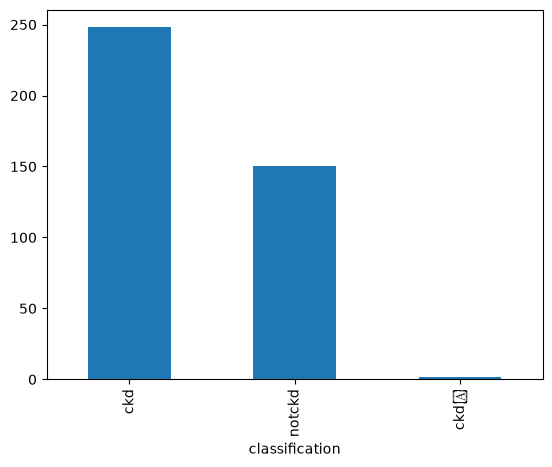

In [3]:
df['classification'].value_counts().plot(kind='bar')

It looks like the dataset has some abnormal/inconsistent datas. Let's check the unique values, mode, and datatype for every column. But, before that, let's remove column 'id' since it is same as an index.

### Remove Unnecessary Column

In [13]:
df = df.drop(columns=['id'])

In [18]:
df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35,7300,4.6,no,no,no,good,no,no,ckd


### Handling Abnormal/Inconsistent Data

In [14]:
print('-----Unique Values, Mode, and Data Type in Each Column-----\n\n')
all_columns = df.columns.tolist()
for column in all_columns:
    print(f'Unique Values in {column}:')
    print(df[column].unique().tolist())
    print()
    print(f'Mode: {df[column].mode()[0]}')
    print()
    print(f'Data Type: {df[column].dtype}')
    print('='*50)

-----Unique Values, Mode, and Data Type in Each Column-----


Unique Values in age:
[48.0, 7.0, 62.0, 51.0, 60.0, 68.0, 24.0, 52.0, 53.0, 50.0, 63.0, 40.0, 47.0, 61.0, 21.0, 42.0, 75.0, 69.0, nan, 73.0, 70.0, 65.0, 76.0, 72.0, 82.0, 46.0, 45.0, 35.0, 54.0, 11.0, 59.0, 67.0, 15.0, 55.0, 44.0, 26.0, 64.0, 56.0, 5.0, 74.0, 38.0, 58.0, 71.0, 34.0, 17.0, 12.0, 43.0, 41.0, 57.0, 8.0, 39.0, 66.0, 81.0, 14.0, 27.0, 83.0, 30.0, 4.0, 3.0, 6.0, 32.0, 80.0, 49.0, 90.0, 78.0, 19.0, 2.0, 33.0, 36.0, 37.0, 23.0, 25.0, 20.0, 29.0, 28.0, 22.0, 79.0]

Mode: 60.0

Data Type: float64
Unique Values in bp:
[80.0, 50.0, 70.0, 90.0, nan, 100.0, 60.0, 110.0, 140.0, 180.0, 120.0]

Mode: 80.0

Data Type: float64
Unique Values in sg:
[1.02, 1.01, 1.005, 1.015, nan, 1.025]

Mode: 1.02

Data Type: float64
Unique Values in al:
[1.0, 4.0, 2.0, 3.0, 0.0, nan, 5.0]

Mode: 0.0

Data Type: float64
Unique Values in su:
[0.0, 3.0, 4.0, 1.0, nan, 2.0, 5.0]

Mode: 0.0

Data Type: float64
Unique Values in rbc:
[nan, 'normal',

We can see that there are some columns with numerical data type that were recognized as string data type because of the leading and trailing characters (spaces, \t, or \n) from a string.

Let's divide the dataset into 2 part: numerical data type only and string data type only.

In [45]:
number_df = df.select_dtypes(include=['number'])
string_df = df.select_dtypes(include=['str'])

In [16]:
number_df

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo
0,48.0,80.0,1.020,1.0,0.0,121.0,36.0,1.2,NaN,NaN,15.4
1,7.0,50.0,1.020,4.0,0.0,NaN,18.0,0.8,NaN,NaN,11.3
2,62.0,80.0,1.010,2.0,3.0,423.0,53.0,1.8,NaN,NaN,9.6
3,48.0,70.0,1.005,4.0,0.0,117.0,56.0,3.8,111.0,2.5,11.2
4,51.0,80.0,1.010,2.0,0.0,106.0,26.0,1.4,NaN,NaN,11.6
...,...,...,...,...,...,...,...,...,...,...,...
395,55.0,80.0,1.020,0.0,0.0,140.0,49.0,0.5,150.0,4.9,15.7
396,42.0,70.0,1.025,0.0,0.0,75.0,31.0,1.2,141.0,3.5,16.5
397,12.0,80.0,1.020,0.0,0.0,100.0,26.0,0.6,137.0,4.4,15.8
398,17.0,60.0,1.025,0.0,0.0,114.0,50.0,1.0,135.0,4.9,14.2


In [17]:
string_df

,rbc,pc,pcc,ba,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,NaN,normal,notpresent,notpresent,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,NaN,normal,notpresent,notpresent,38,6000,NaN,no,no,no,good,no,no,ckd
2,normal,normal,notpresent,notpresent,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,normal,abnormal,present,notpresent,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,normal,normal,notpresent,notpresent,35,7300,4.6,no,no,no,good,no,no,ckd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,normal,normal,notpresent,notpresent,47,6700,4.9,no,no,no,good,no,no,notckd
396,normal,normal,notpresent,notpresent,54,7800,6.2,no,no,no,good,no,no,notckd
397,normal,normal,notpresent,notpresent,49,6600,5.4,no,no,no,good,no,no,notckd
398,normal,normal,notpresent,notpresent,51,7200,5.9,no,no,no,good,no,no,notckd


Let's removes leading and trailing characters (spaces, \t, or \n) from a string.

In [48]:
string_df = string_df.map(lambda data: data.strip() if isinstance(data, str) else data)
string_df

,rbc,pc,pcc,ba,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,NaN,normal,notpresent,notpresent,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,NaN,normal,notpresent,notpresent,38,6000,NaN,no,no,no,good,no,no,ckd
2,normal,normal,notpresent,notpresent,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,normal,abnormal,present,notpresent,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,normal,normal,notpresent,notpresent,35,7300,4.6,no,no,no,good,no,no,ckd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,normal,normal,notpresent,notpresent,47,6700,4.9,no,no,no,good,no,no,notckd
396,normal,normal,notpresent,notpresent,54,7800,6.2,no,no,no,good,no,no,notckd
397,normal,normal,notpresent,notpresent,49,6600,5.4,no,no,no,good,no,no,notckd
398,normal,normal,notpresent,notpresent,51,7200,5.9,no,no,no,good,no,no,notckd


Re-check the unique values.

In [49]:
print('-----Unique Values, Mode, and Data Type in Each Column-----\n\n')
string_columns = string_df.columns.tolist()
for column in string_columns:
    print(f'Unique Values in {column}:')
    print(string_df[column].unique().tolist())
    print()
    print(f'Mode: {string_df[column].mode()[0]}')
    print()
    print(f'Data Type: {string_df[column].dtype}')
    print('='*50)

-----Unique Values, Mode, and Data Type in Each Column-----


Unique Values in rbc:
[nan, 'normal', 'abnormal']

Mode: normal

Data Type: str
Unique Values in pc:
['normal', 'abnormal', nan]

Mode: normal

Data Type: str
Unique Values in pcc:
['notpresent', 'present', nan]

Mode: notpresent

Data Type: str
Unique Values in ba:
['notpresent', 'present', nan]

Mode: notpresent

Data Type: str
Unique Values in pcv:
['44', '38', '31', '32', '35', '39', '36', '33', '29', '28', nan, '16', '24', '37', '30', '34', '40', '45', '27', '48', '?', '52', '14', '22', '18', '42', '17', '46', '23', '19', '25', '41', '26', '15', '21', '43', '20', '47', '9', '49', '50', '53', '51', '54']

Mode: 41

Data Type: str
Unique Values in wc:
['7800', '6000', '7500', '6700', '7300', nan, '6900', '9600', '12100', '4500', '12200', '11000', '3800', '11400', '5300', '9200', '6200', '8300', '8400', '10300', '9800', '9100', '7900', '6400', '8600', '18900', '21600', '4300', '8500', '11300', '7200', '7700', '14600', '630

We still need to change '?' to NaN.

In [54]:
string_df = string_df.replace('?', np.nan)

Re-check the unique values.

In [55]:
print('-----Unique Values, Mode, and Data Type in Each Column-----\n\n')
string_columns = string_df.columns.tolist()
for column in string_columns:
    print(f'Unique Values in {column}:')
    print(string_df[column].unique().tolist())
    print()
    print(f'Mode: {string_df[column].mode()[0]}')
    print()
    print(f'Data Type: {string_df[column].dtype}')
    print('='*50)

-----Unique Values, Mode, and Data Type in Each Column-----


Unique Values in rbc:
[nan, 'normal', 'abnormal']

Mode: normal

Data Type: str
Unique Values in pc:
['normal', 'abnormal', nan]

Mode: normal

Data Type: str
Unique Values in pcc:
['notpresent', 'present', nan]

Mode: notpresent

Data Type: str
Unique Values in ba:
['notpresent', 'present', nan]

Mode: notpresent

Data Type: str
Unique Values in pcv:
['44', '38', '31', '32', '35', '39', '36', '33', '29', '28', nan, '16', '24', '37', '30', '34', '40', '45', '27', '48', '52', '14', '22', '18', '42', '17', '46', '23', '19', '25', '41', '26', '15', '21', '43', '20', '47', '9', '49', '50', '53', '51', '54']

Mode: 41

Data Type: str
Unique Values in wc:
['7800', '6000', '7500', '6700', '7300', nan, '6900', '9600', '12100', '4500', '12200', '11000', '3800', '11400', '5300', '9200', '6200', '8300', '8400', '10300', '9800', '9100', '7900', '6400', '8600', '18900', '21600', '4300', '8500', '11300', '7200', '7700', '14600', '6300', '

Convert 'pcv', 'wc', and 'rc' data type to float.

In [56]:
string_df['pcv'] = string_df['pcv'].astype(float)
string_df['wc'] = string_df['wc'].astype(float)
string_df['rc'] = string_df['rc'].astype(float)

Concat the number_df and string_df to get back the full dataframe.

In [57]:
df = pd.concat([number_df, string_df], axis=1)
df

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,121.0,36.0,1.2,NaN,NaN,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,18.0,0.8,NaN,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,423.0,53.0,1.8,NaN,NaN,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,117.0,56.0,3.8,111.0,2.5,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,106.0,26.0,1.4,NaN,NaN,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,55.0,80.0,1.020,0.0,0.0,140.0,49.0,0.5,150.0,4.9,...,47.0,6700.0,4.9,no,no,no,good,no,no,notckd
396,42.0,70.0,1.025,0.0,0.0,75.0,31.0,1.2,141.0,3.5,...,54.0,7800.0,6.2,no,no,no,good,no,no,notckd
397,12.0,80.0,1.020,0.0,0.0,100.0,26.0,0.6,137.0,4.4,...,49.0,6600.0,5.4,no,no,no,good,no,no,notckd
398,17.0,60.0,1.025,0.0,0.0,114.0,50.0,1.0,135.0,4.9,...,51.0,7200.0,5.9,no,no,no,good,no,no,notckd


In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             391 non-null    float64
 1   bp              388 non-null    float64
 2   sg              353 non-null    float64
 3   al              354 non-null    float64
 4   su              351 non-null    float64
 5   bgr             356 non-null    float64
 6   bu              381 non-null    float64
 7   sc              383 non-null    float64
 8   sod             313 non-null    float64
 9   pot             312 non-null    float64
 10  hemo            348 non-null    float64
 11  rbc             248 non-null    str    
 12  pc              335 non-null    str    
 13  pcc             396 non-null    str    
 14  ba              396 non-null    str    
 15  pcv             329 non-null    float64
 16  wc              294 non-null    float64
 17  rc              269 non-null    float64
 18  h

### Handling Missing Values

In [59]:
df.isna().sum()

age                 9
bp                 12
sg                 47
al                 46
su                 49
bgr                44
bu                 19
sc                 17
sod                87
pot                88
hemo               52
rbc               152
pc                 65
pcc                 4
ba                  4
pcv                71
wc                106
rc                131
htn                 2
dm                  2
cad                 2
appet               1
pe                  1
ane                 1
classification      0
dtype: int64

### Train-Test Split

Before handling the missing values, split the the data into train, validation, and test set. Here, we are using 80:10:10 ratio for the train, validation, and test set, respectively. 

We must split our data first, to avoid data leakage

In [83]:
from sklearn.model_selection import train_test_split

target = 'classification'
y = df[target].values

X_df = df.drop(columns=[target])

X_train_df, X_valtest_df, y_train, y_valtest = train_test_split(X_df, y, test_size=0.2, random_state=42)
X_val_df, X_test_df, y_val, y_test = train_test_split(X_valtest_df, y_valtest, test_size=0.5, random_state=42)

print(f'X_train_df shape:{X_train_df.shape}')
print(f'X_val_df shape:{X_val_df.shape}')
print(f'X_test_df shape:{X_test_df.shape}')
print(f'y_train shape:{y_train.shape}')
print(f'y_val shape:{y_val.shape}')
print(f'y_test shape:{y_test.shape}')

X_train_df shape:(320, 24)
X_val_df shape:(40, 24)
X_test_df shape:(40, 24)
y_train shape:(320,)
y_val shape:(40,)
y_test shape:(40,)


In [84]:
y_train

<StringArray>
[   'ckd',    'ckd',    'ckd', 'notckd', 'notckd',    'ckd',    'ckd',
 'notckd',    'ckd',    'ckd',
 ...
    'ckd',    'ckd', 'notckd',    'ckd',    'ckd',    'ckd',    'ckd',
 'notckd', 'notckd',    'ckd']
Length: 320, dtype: str

In [85]:
y_val

<StringArray>
[   'ckd',    'ckd', 'notckd',    'ckd', 'notckd',    'ckd', 'notckd',
    'ckd',    'ckd',    'ckd',    'ckd',    'ckd',    'ckd',    'ckd',
    'ckd',    'ckd',    'ckd',    'ckd',    'ckd', 'notckd',    'ckd',
 'notckd', 'notckd',    'ckd',    'ckd',    'ckd',    'ckd', 'notckd',
    'ckd', 'notckd', 'notckd',    'ckd',    'ckd', 'notckd', 'notckd',
    'ckd',    'ckd',    'ckd',    'ckd', 'notckd']
Length: 40, dtype: str

In [86]:
y_test

<StringArray>
['notckd',    'ckd', 'notckd',    'ckd',    'ckd', 'notckd',    'ckd',
 'notckd',    'ckd',    'ckd',    'ckd',    'ckd', 'notckd',    'ckd',
 'notckd', 'notckd',    'ckd', 'notckd',    'ckd', 'notckd',    'ckd',
    'ckd',    'ckd',    'ckd',    'ckd', 'notckd',    'ckd', 'notckd',
 'notckd',    'ckd',    'ckd', 'notckd',    'ckd',    'ckd',    'ckd',
 'notckd', 'notckd', 'notckd',    'ckd',    'ckd']
Length: 40, dtype: str

Impute the numerical features with median and categorical features with mode.

In [87]:
# first, divide the data into 2 parts: numerical features only and categorical features only
X_train_num_df = X_train_df.select_dtypes(include=['number'])
X_val_num_df = X_val_df.select_dtypes(include=['number'])
X_test_num_df = X_test_df.select_dtypes(include=['number'])

X_train_cat_df = X_train_df.select_dtypes(include=['str'])
X_val_cat_df = X_val_df.select_dtypes(include=['str'])
X_test_cat_df = X_test_df.select_dtypes(include=['str'])

print(f'X_train_num_df shape:{X_train_num_df.shape}')
print(f'X_val_num_df shape:{X_val_num_df.shape}')
print(f'X_test_num_df shape:{X_test_num_df.shape}')
print(f'X_train_cat_df shape:{X_train_cat_df.shape}')
print(f'X_val_cat_df shape:{X_val_cat_df.shape}')
print(f'X_test_cat_df shape:{X_test_cat_df.shape}')

X_train_num_df shape:(320, 14)
X_val_num_df shape:(40, 14)
X_test_num_df shape:(40, 14)
X_train_cat_df shape:(320, 10)
X_val_cat_df shape:(40, 10)
X_test_cat_df shape:(40, 10)


In [88]:
# impute missing values using data train's feature median for numerical features
num_columns = X_train_num_df.columns.tolist()
for column in num_columns:
    train_column_median = X_train_num_df[column].median()
    X_train_num_df[column] = X_train_num_df[column].fillna(train_column_median)
    X_val_num_df[column] = X_val_num_df[column].fillna(train_column_median)
    X_test_num_df[column] = X_test_num_df[column].fillna(train_column_median)

# impute missing values using data train's feature mode for categorical features
cat_columns = X_train_cat_df.columns.tolist()
for column in cat_columns:
    train_column_mode = X_train_cat_df[column].mode()[0]
    X_train_cat_df[column] = X_train_cat_df[column].fillna(train_column_mode)
    X_val_cat_df[column] = X_val_cat_df[column].fillna(train_column_mode)
    X_test_cat_df[column] = X_test_cat_df[column].fillna(train_column_mode)

Re-check the missing values.

In [89]:
X_train_num_df_nan = X_train_num_df.isna().sum()
X_val_num_df_nan = X_val_num_df.isna().sum()
X_test_num_df_nan = X_test_num_df.isna().sum()
X_train_cat_df_nan = X_train_cat_df.isna().sum()
X_val_cat_df_nan = X_val_cat_df.isna().sum()
X_test_cat_df_nan = X_test_cat_df.isna().sum()

print(X_train_num_df_nan, '\n')
print(X_val_num_df_nan, '\n')
print(X_test_num_df_nan, '\n')
print(X_train_cat_df_nan, '\n')
print(X_val_cat_df_nan, '\n')
print(X_test_cat_df_nan, '\n')

age     0
bp      0
sg      0
al      0
su      0
bgr     0
bu      0
sc      0
sod     0
pot     0
hemo    0
pcv     0
wc      0
rc      0
dtype: int64 

age     0
bp      0
sg      0
al      0
su      0
bgr     0
bu      0
sc      0
sod     0
pot     0
hemo    0
pcv     0
wc      0
rc      0
dtype: int64 

age     0
bp      0
sg      0
al      0
su      0
bgr     0
bu      0
sc      0
sod     0
pot     0
hemo    0
pcv     0
wc      0
rc      0
dtype: int64 

rbc      0
pc       0
pcc      0
ba       0
htn      0
dm       0
cad      0
appet    0
pe       0
ane      0
dtype: int64 

rbc      0
pc       0
pcc      0
ba       0
htn      0
dm       0
cad      0
appet    0
pe       0
ane      0
dtype: int64 

rbc      0
pc       0
pcc      0
ba       0
htn      0
dm       0
cad      0
appet    0
pe       0
ane      0
dtype: int64 



## Numerical Features Scaling

The numerical features exhibit vastly different scales and measurement ranges. MinMaxScaler is applied to transform all numerical features to possess minimum value 0 and maximum value 1.

In [90]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_num = X_train_num_df.values
X_val_num = X_val_num_df.values
X_test_num = X_test_num_df.values

X_train_num_scaled = scaler.fit_transform(X_train_num)
X_val_num_scaled = scaler.transform(X_val_num)
X_test_num_scaled = scaler.transform(X_test_num)

X_train_num_scaled_df = pd.DataFrame(data=X_train_num_scaled, columns=num_columns)
X_val_num_scaled_df = pd.DataFrame(data=X_val_num_scaled, columns=num_columns)
X_test_num_scaled_df = pd.DataFrame(data=X_test_num_scaled, columns=num_columns)

In [99]:
X_train_num_scaled_df.head()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc
0,0.522727,0.153846,0.00,0.8,0.0,0.111905,0.120735,0.044974,0.671924,0.000000,0.551020,0.511111,0.185950,0.305085
1,0.659091,0.384615,1.00,0.0,0.6,0.459524,0.044619,0.011905,0.823344,0.040449,0.653061,0.622222,0.380165,0.372881
2,0.863636,0.076923,0.75,0.0,0.0,0.104762,0.167979,0.033069,0.823344,0.076404,0.333333,0.333333,0.241736,0.457627
3,0.431818,0.230769,1.00,0.0,0.0,0.166667,0.000000,0.010582,0.823344,0.056180,0.809524,0.866667,0.338843,0.406780
4,0.193182,0.230769,0.75,0.0,0.0,0.088095,0.034121,0.003968,0.861199,0.038202,0.768707,0.777778,0.241736,0.457627


In [100]:
X_val_num_scaled_df.head()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc
0,0.625000,0.230769,0.50,0.0,0.0,0.119048,0.099738,0.015873,0.842271,0.042697,0.557823,0.600000,0.206612,0.288136
1,0.647727,0.384615,0.50,0.8,0.4,0.440476,0.320210,0.164021,0.823344,0.071910,0.285714,0.244444,0.314050,0.305085
2,0.636364,0.153846,1.00,0.0,0.0,0.042857,0.015748,0.009259,0.899054,0.022472,0.904762,0.977778,0.285124,0.525424
3,0.784091,0.076923,0.75,0.6,0.4,0.842857,0.099738,0.014550,0.804416,0.033708,0.530612,0.488889,0.241736,0.457627
4,0.602273,0.230769,0.75,0.0,0.0,0.150000,0.018373,0.010582,0.823344,0.051685,0.687075,0.711111,0.190083,0.542373


In [101]:
X_test_num_scaled_df.head()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc
0,0.602273,0.230769,0.75,0.0,0.0,0.166667,0.102362,0.001323,0.917981,0.053933,0.857143,0.844444,0.185950,0.474576
1,0.193182,0.153846,0.75,0.0,0.0,0.126190,0.078740,0.010582,0.842271,0.042697,0.571429,0.711111,0.194215,0.457627
2,0.386364,0.230769,1.00,0.0,0.0,0.035714,0.015748,0.009259,0.867508,0.035955,0.850340,0.777778,0.148760,0.711864
3,0.340909,0.307692,1.00,0.2,0.0,0.126190,0.559055,0.234127,0.684543,0.089888,0.163265,0.133333,0.016529,0.118644
4,0.659091,0.307692,0.75,0.0,0.0,0.473810,0.107612,0.031746,0.842271,0.026966,0.571429,0.577778,0.241736,0.457627


## Categorical Features Encoding

In [94]:
y_train_encoded = np.where(y_train == 'ckd', 1, 0)
y_val_encoded = np.where(y_val == 'ckd', 1, 0)
y_test_encoded = np.where(y_test == 'ckd', 1, 0)

X_train_cat_encoded_df = pd.get_dummies(X_train_cat_df, prefix=cat_columns, drop_first=True, dtype=int)
X_val_cat_encoded_df = pd.get_dummies(X_val_cat_df, prefix=cat_columns, drop_first=True, dtype=int)
X_test_cat_encoded_df = pd.get_dummies(X_test_cat_df, prefix=cat_columns, drop_first=True, dtype=int)

In [95]:
print(f'y_train_encoded: {y_train_encoded}\n')
print(f'y_val_encoded: {y_val_encoded}\n')
print(f'y_test_encoded: {y_test_encoded}')

y_train_encoded: [1 1 1 0 0 1 1 0 1 1 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 0 0 1 0 0 0 0 1 1
 0 0 0 1 1 1 0 1 1 0 0 1 1 0 1 0 1 1 1 1 0 1 0 1 1 0 1 1 0 1 1 1 0 1 0 0 1
 1 1 1 1 0 0 0 1 0 1 0 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 0 1 1
 1 0 1 0 0 0 0 0 0 1 1 0 1 0 1 1 1 0 1 1 1 1 0 0 1 0 0 0 0 0 1 0 1 1 1 1 0
 1 1 1 1 1 1 1 0 1 0 0 0 0 1 1 0 1 1 0 1 1 0 1 1 1 0 1 0 1 1 1 1 1 1 1 1 1
 1 0 0 1 1 1 1 0 0 1 1 0 1 0 0 1 0 0 1 1 0 1 1 1 1 1 1 1 0 1 0 1 0 1 0 0 1
 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 0 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 0 0 1 1 1 1
 1 1 1 0 1 0 1 0 0 1 1 0 1 0 1 0 0 1 0 0 0 1 1 1 1 1 0 1 1 1 1 0 1 0 1 0 1
 0 1 0 0 0 0 1 1 1 0 1 0 1 0 1 1 0 1 1 1 1 0 0 1]

y_val_encoded: [1 1 0 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 0 1 1 0 0 1 1
 1 1 0]

y_test_encoded: [0 1 0 1 1 0 1 0 1 1 1 1 0 1 0 0 1 0 1 0 1 1 1 1 1 0 1 0 0 1 1 0 1 1 1 0 0
 0 1 1]


In [96]:
X_train_cat_encoded_df.head()

,rbc_normal,pc_normal,pcc_present,ba_present,htn_yes,dm_yes,cad_yes,appet_poor,pe_yes,ane_yes
3,1,0,1,0,1,0,0,1,1,1
18,1,1,0,0,1,1,1,0,0,0
202,1,1,0,0,0,1,0,0,0,1
250,1,1,0,0,0,0,0,0,0,0
274,1,1,0,0,0,0,0,0,0,0


In [97]:
X_val_cat_encoded_df.head()

,rbc_normal,pc_normal,pcc_present,ba_present,htn_yes,dm_yes,cad_yes,appet_poor,pe_yes,ane_yes
227,1,1,0,0,1,1,0,0,0,0
210,1,1,0,0,1,1,1,0,0,1
376,1,1,0,0,0,0,0,0,0,0
158,1,1,1,0,1,1,1,0,0,0
266,1,1,0,0,0,0,0,0,0,0


In [98]:
X_test_cat_encoded_df.head()

,rbc_normal,pc_normal,pcc_present,ba_present,htn_yes,dm_yes,cad_yes,appet_poor,pe_yes,ane_yes
395,1,1,0,0,0,0,0,0,0,0
209,1,1,0,0,0,0,0,0,0,0
391,1,1,0,0,0,0,0,0,0,0
193,0,0,0,0,1,1,0,1,1,1
231,1,1,0,0,1,1,1,0,1,0


Concat the scaled numerical dataframe and the encoded categorical dataframe.

In [102]:
X_train_preprocessed_df = pd.concat([X_train_num_scaled_df, X_train_cat_encoded_df.reset_index(drop=True)], axis=1)
X_val_preprocessed_df = pd.concat([X_val_num_scaled_df, X_val_cat_encoded_df.reset_index(drop=True)], axis=1)
X_test_preprocessed_df = pd.concat([X_test_num_scaled_df, X_test_cat_encoded_df.reset_index(drop=True)], axis=1)

In [104]:
X_train_preprocessed_df

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,...,rbc_normal,pc_normal,pcc_present,ba_present,htn_yes,dm_yes,cad_yes,appet_poor,pe_yes,ane_yes
0,0.522727,0.153846,0.00,0.8,0.0,0.111905,0.120735,0.044974,0.671924,0.000000,...,1,0,1,0,1,0,0,1,1,1
1,0.659091,0.384615,1.00,0.0,0.6,0.459524,0.044619,0.011905,0.823344,0.040449,...,1,1,0,0,1,1,1,0,0,0
2,0.863636,0.076923,0.75,0.0,0.0,0.104762,0.167979,0.033069,0.823344,0.076404,...,1,1,0,0,0,1,0,0,0,1
3,0.431818,0.230769,1.00,0.0,0.0,0.166667,0.000000,0.010582,0.823344,0.056180,...,1,1,0,0,0,0,0,0,0,0
4,0.193182,0.230769,0.75,0.0,0.0,0.088095,0.034121,0.003968,0.861199,0.038202,...,1,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,0.500000,0.076923,0.25,0.2,0.0,0.221429,0.215223,0.038360,0.861199,0.033708,...,1,1,0,0,1,1,0,0,0,0
316,0.545455,0.307692,0.75,0.0,0.0,0.045238,0.283465,0.075397,0.772871,0.042697,...,1,1,0,0,1,1,0,0,1,1
317,0.238636,0.230769,1.00,0.0,0.0,0.097619,0.062992,0.009259,0.886435,0.033708,...,1,1,0,0,0,0,0,0,0,0
318,0.409091,0.230769,0.75,0.0,0.0,0.069048,0.023622,0.001323,0.899054,0.022472,...,1,1,0,0,0,0,0,0,0,0


In [105]:
X_val_preprocessed_df

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,...,rbc_normal,pc_normal,pcc_present,ba_present,htn_yes,dm_yes,cad_yes,appet_poor,pe_yes,ane_yes
0,0.625000,0.230769,0.50,0.0,0.0,0.119048,0.099738,0.015873,0.842271,0.042697,...,1,1,0,0,1,1,0,0,0,0
1,0.647727,0.384615,0.50,0.8,0.4,0.440476,0.320210,0.164021,0.823344,0.071910,...,1,1,0,0,1,1,1,0,0,1
2,0.636364,0.153846,1.00,0.0,0.0,0.042857,0.015748,0.009259,0.899054,0.022472,...,1,1,0,0,0,0,0,0,0,0
3,0.784091,0.076923,0.75,0.6,0.4,0.842857,0.099738,0.014550,0.804416,0.033708,...,1,1,1,0,1,1,1,0,0,0
4,0.602273,0.230769,0.75,0.0,0.0,0.150000,0.018373,0.010582,0.823344,0.051685,...,1,1,0,0,0,0,0,0,0,0
5,0.806818,0.307692,0.50,0.6,0.0,0.088095,0.060367,0.014550,0.861199,0.047191,...,1,0,1,0,0,0,0,1,0,0
6,0.352273,0.076923,1.00,0.0,0.0,0.023810,0.039370,0.006614,0.892744,0.022472,...,1,1,0,0,0,0,0,0,0,0
7,0.670455,0.307692,0.50,0.0,0.4,0.126190,0.078740,0.010582,0.842271,0.042697,...,1,1,0,0,0,1,0,1,0,1
8,0.659091,0.307692,0.50,0.6,0.0,0.009524,0.039370,0.009259,0.867508,0.015730,...,1,1,0,0,1,1,0,0,1,0
9,0.590909,0.153846,0.75,0.0,0.0,0.054762,0.380577,0.091270,0.804416,0.053933,...,1,1,0,0,1,1,0,0,0,0


In [106]:
X_test_preprocessed_df

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,...,rbc_normal,pc_normal,pcc_present,ba_present,htn_yes,dm_yes,cad_yes,appet_poor,pe_yes,ane_yes
0,0.602273,0.230769,0.75,0.0,0.0,0.166667,0.102362,0.001323,0.917981,0.053933,...,1,1,0,0,0,0,0,0,0,0
1,0.193182,0.153846,0.75,0.0,0.0,0.126190,0.078740,0.010582,0.842271,0.042697,...,1,1,0,0,0,0,0,0,0,0
2,0.386364,0.230769,1.00,0.0,0.0,0.035714,0.015748,0.009259,0.867508,0.035955,...,1,1,0,0,0,0,0,0,0,0
3,0.340909,0.307692,1.00,0.2,0.0,0.126190,0.559055,0.234127,0.684543,0.089888,...,0,0,0,0,1,1,0,1,1,1
4,0.659091,0.307692,0.75,0.0,0.0,0.473810,0.107612,0.031746,0.842271,0.026966,...,1,1,0,0,1,1,1,0,1,0
5,0.602273,0.230769,0.75,0.0,0.0,0.114286,0.020997,0.006614,0.823344,0.024719,...,1,1,0,0,0,0,0,0,0,0
6,0.579545,0.307692,0.75,0.4,0.0,0.000000,0.254593,0.089947,0.690852,0.026966,...,0,0,1,0,1,1,0,1,0,1
7,0.625000,0.076923,0.75,0.0,0.0,0.083333,0.102362,0.010582,0.917981,0.049438,...,1,1,0,0,0,0,0,0,0,0
8,0.806818,0.384615,0.25,0.6,0.4,0.535714,0.209974,0.068783,0.854890,0.008989,...,0,0,1,0,1,1,1,1,0,0
9,0.840909,0.153846,0.50,0.6,0.8,0.126190,0.404199,0.123016,0.798107,0.042697,...,1,0,1,0,1,1,1,1,1,0


## Feature Selection Using Tree-Based Model's Feature Importance

Select top-10 features based on tree-based model's feature importance.

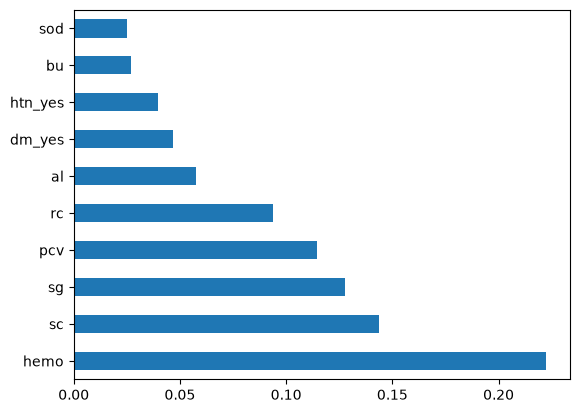

Top Selected Features:

hemo       0.222369
sc         0.143829
sg         0.127781
pcv        0.114325
rc         0.093851
al         0.057440
dm_yes     0.046808
htn_yes    0.039621
bu         0.026890
sod        0.025040
dtype: float64


In [109]:
from sklearn.ensemble import RandomForestClassifier

tree_model = RandomForestClassifier(n_estimators=100, random_state=42)
tree_model.fit(X_train_preprocessed_df.values, y_train_encoded)

feature_importances = pd.Series(tree_model.feature_importances_, index=X_train_preprocessed_df.columns).sort_values(ascending=False)
feature_importances.nlargest(10).plot(kind='barh')
plt.show()

top_features = feature_importances.head(10).index.tolist()
print("Top Selected Features:\n")
print(feature_importances.head(10))

X_train_selected_df = X_train_preprocessed_df[top_features]
X_val_selected_df = X_val_preprocessed_df[top_features]
X_test_selected_df = X_test_preprocessed_df[top_features]

In [112]:
X_train_selected_df.head()

,hemo,sc,sg,pcv,rc,al,dm_yes,htn_yes,bu,sod
0,0.551020,0.044974,0.00,0.511111,0.305085,0.8,0,1,0.120735,0.671924
1,0.653061,0.011905,1.00,0.622222,0.372881,0.0,1,1,0.044619,0.823344
2,0.333333,0.033069,0.75,0.333333,0.457627,0.0,1,0,0.167979,0.823344
3,0.809524,0.010582,1.00,0.866667,0.406780,0.0,0,0,0.000000,0.823344
4,0.768707,0.003968,0.75,0.777778,0.457627,0.0,0,0,0.034121,0.861199


In [113]:
X_val_selected_df.head()

,hemo,sc,sg,pcv,rc,al,dm_yes,htn_yes,bu,sod
0,0.557823,0.015873,0.50,0.600000,0.288136,0.0,1,1,0.099738,0.842271
1,0.285714,0.164021,0.50,0.244444,0.305085,0.8,1,1,0.320210,0.823344
2,0.904762,0.009259,1.00,0.977778,0.525424,0.0,0,0,0.015748,0.899054
3,0.530612,0.014550,0.75,0.488889,0.457627,0.6,1,1,0.099738,0.804416
4,0.687075,0.010582,0.75,0.711111,0.542373,0.0,0,0,0.018373,0.823344


In [114]:
X_test_selected_df.head()

,hemo,sc,sg,pcv,rc,al,dm_yes,htn_yes,bu,sod
0,0.857143,0.001323,0.75,0.844444,0.474576,0.0,0,0,0.102362,0.917981
1,0.571429,0.010582,0.75,0.711111,0.457627,0.0,0,0,0.078740,0.842271
2,0.850340,0.009259,1.00,0.777778,0.711864,0.0,0,0,0.015748,0.867508
3,0.163265,0.234127,1.00,0.133333,0.118644,0.2,1,1,0.559055,0.684543
4,0.571429,0.031746,0.75,0.577778,0.457627,0.0,1,1,0.107612,0.842271


## Train Model

In [122]:
X_train_selected = X_train_selected_df.values
X_val_selected = X_val_selected_df.values
X_test_selected = X_test_selected_df.values

y_train_reshaped = y_train_encoded.reshape(-1, 1)
y_val_reshaped = y_val_encoded.reshape(-1, 1)
y_test_reshaped = y_test_encoded.reshape(-1, 1)

Build the model. 

Here, we are using Multi Layer Perceptron (MLP) model with 2 layers: 

- First layer with 10 neurons and using ReLU activation function;

- Second layer with 5 neurons and using ReLU activation function.

The output layer consists of 1 neuron with Sigmoid activation function since this is a binary classification problem.

Then, the model is compiled using AdamW optimizer with learning rate $10^{-3}$ and the binary crossentropy loss function.

In [123]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape = (X_train_selected.shape[1],)),
    tf.keras.layers.Dense(10, activation = 'relu'),
    tf.keras.layers.Dense(5, activation = 'relu'),
    tf.keras.layers.Dense(1, activation = 'sigmoid')
])

opt = tf.keras.optimizers.AdamW(learning_rate=1e-3)
model.compile(optimizer = opt, loss = 'binary_crossentropy',
              metrics=['accuracy'])

model.summary()

C:\Users\HYPE AMD\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 171 (684.00 B)

 Trainable params: 171 (684.00 B)

 Non-trainable params: 0 (0.00 B)

Train the model with early stopping.

In [124]:
early_stop = tf.keras.callbacks.EarlyStopping(patience=5, monitor='val_loss',
                                              restore_best_weights=True,
                                              verbose=1)

history = model.fit(X_train_selected, y_train_reshaped,
                              validation_data=(X_val_selected, y_val_reshaped),
                              epochs=50, batch_size=32,
                              callbacks=[early_stop])

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6187 - loss: 0.6585 - val_accuracy: 0.7000 - val_loss: 0.6487
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6187 - loss: 0.6447 - val_accuracy: 0.7000 - val_loss: 0.6337
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6187 - loss: 0.6299 - val_accuracy: 0.7000 - val_loss: 0.6173
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6187 - loss: 0.6146 - val_accuracy: 0.7000 - val_loss: 0.6020
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6187 - loss: 0.5998 - val_accuracy: 0.7000 - val_loss: 0.5858
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6187 - loss: 0.5858 - val_accuracy: 0.7000 - val_loss: 0.5693
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6187 - loss: 0.5726 - val_accuracy: 0.7000 - val_loss: 0.5529
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6187 - loss: 0.5595 - val_accuracy: 0.7000 - val_lo

## Model Evaluation

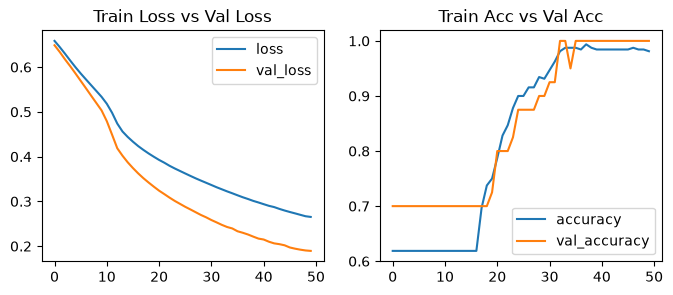

In [125]:
loss = history.history['loss']
val_loss = history.history['val_loss']
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
epochs = range(len(loss))

fig, ax = plt.subplots(1, 2, figsize=(8,3))
ax[0].plot(epochs, loss)
ax[0].plot(epochs, val_loss)
ax[0].legend(['loss', 'val_loss'], loc='upper right')
ax[0].set_title('Train Loss vs Val Loss')
ax[1].plot(epochs, accuracy)
ax[1].plot(epochs, val_accuracy)
ax[1].legend(['accuracy', 'val_accuracy'], loc='lower right')
ax[1].set_title('Train Acc vs Val Acc')
plt.show()

In [126]:
model.evaluate(X_test_selected, y_test_reshaped)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - loss: 0.2587


[0.2586838901042938, 1.0]

In [127]:
y_pred_prob = model.predict(X_test_selected)
y_pred = (y_pred_prob > 0.5).astype(int)
print(y_pred)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
[[0]
 [1]
 [0]
 [1]
 [1]
 [0]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]]


In [128]:
y_pred = y_pred.reshape(-1)
y_pred

array([0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1])

--- Classification Report ---
Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      1.00      1.00        24

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

--- Confusion Matrix ---


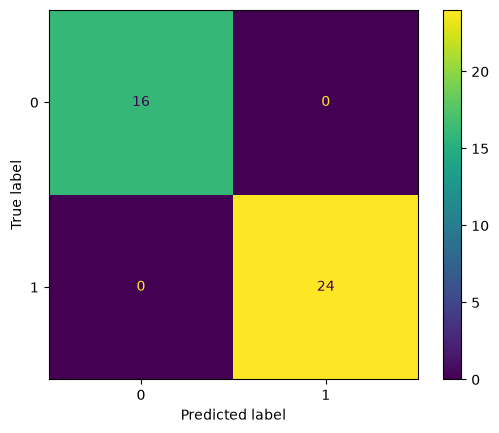

In [129]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("--- Classification Report ---")
report = classification_report(y_test_encoded, y_pred)
print('Classification Report:\n')
print(report)

print("--- Confusion Matrix ---")
cm = confusion_matrix(y_test_encoded, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()